# 🧭 Maze Escape — Learning with the Incremental Mean
**Monte Carlo Reinforcement Learning in Python**

An agent learns to escape a 6×6 maze using only experience from complete episodes.
Action values are estimated with the **Incremental Mean**:

$$N(s,a) \leftarrow N(s,a)+1 \qquad Q(s,a) \leftarrow Q(s,a)+\frac{1}{N(s,a)}\big(G-Q(s,a)\big)$$

**Notebook outline:** 1. Setup · 2. Maze & actions · 3. Rewards & environment · 4. Agent · 5. Training · 6. Final Q-values · 7. Learned policy · 8. Plots & discussion

## 1. Setup

In [1]:
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

random.seed(42)
np.random.seed(42)

## 2. The Maze (States) and Actions
* **State** = the agent's position `(row, col)`
* Legend: `S` start · `G` goal (exit) · `#` wall · `T` trap · `.` free cell
* **Actions:** UP, DOWN, LEFT, RIGHT

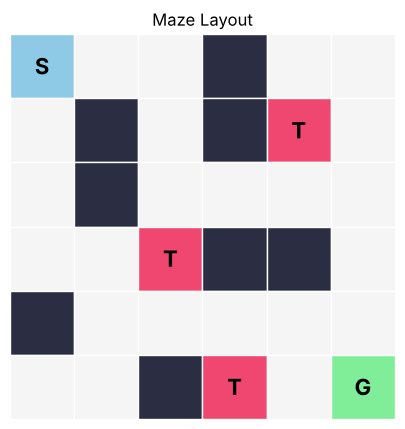

In [2]:
MAZE = [
    "S . . # . .",
    ". # . # T .",
    ". # . . . .",
    ". . T # # .",
    "# . . . . .",
    ". . # T . G",
]
MAZE = [row.split() for row in MAZE]
ROWS, COLS = len(MAZE), len(MAZE[0])

ACTIONS = {0: ("UP", (-1, 0)), 1: ("DOWN", (1, 0)),
           2: ("LEFT", (0, -1)), 3: ("RIGHT", (0, 1))}
ARROWS = {0: "↑", 1: "↓", 2: "←", 3: "→"}
N_ACTIONS = len(ACTIONS)

def draw_maze(path=None, title="Maze Layout"):
    colors = {".": "#F5F5F5", "#": "#2B2D42", "S": "#8ECAE6", "G": "#80ED99", "T": "#EF476F"}
    fig, ax = plt.subplots(figsize=(5, 5))
    for r in range(ROWS):
        for c in range(COLS):
            ax.add_patch(plt.Rectangle((c, ROWS-1-r), 1, 1, facecolor=colors[MAZE[r][c]], edgecolor="white"))
            if MAZE[r][c] in "SGT":
                ax.text(c+.5, ROWS-1-r+.5, MAZE[r][c], ha="center", va="center", fontsize=16, weight="bold")
    if path:
        ax.plot([c+.5 for _, c in path], [ROWS-1-r+.5 for r, _ in path], color="#FF6584", lw=3, marker="o")
    ax.set_xlim(0, COLS); ax.set_ylim(0, ROWS); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)
    plt.show()

draw_maze()

## 3. Reward Function and Game Rules (Transitions)

| Outcome | Reward | Episode ends? |
|---|---|---|
| Normal move | −1 | No |
| Wall / border (agent stays) | −5 | No |
| Trap | −20 | Yes |
| Exit | +50 | Yes |
| 60 steps reached | – | Yes (time-out) |

In [3]:
REWARD_STEP, REWARD_WALL, REWARD_TRAP, REWARD_GOAL = -1, -5, -20, +50
MAX_STEPS = 60

class MazeEscape:
    def __init__(self, layout):
        self.layout = layout
        self.start = self._find("S")
        self.goal = self._find("G")
        self.state, self.steps = self.start, 0

    def _find(self, symbol):
        for r in range(ROWS):
            for c in range(COLS):
                if self.layout[r][c] == symbol:
                    return (r, c)

    def reset(self):
        self.state, self.steps = self.start, 0
        return self.state

    def step(self, action):
        self.steps += 1
        dr, dc = ACTIONS[action][1]
        r, c = self.state
        nr, nc = r + dr, c + dc

        if not (0 <= nr < ROWS and 0 <= nc < COLS) or self.layout[nr][nc] == "#":
            reward, done = REWARD_WALL, False          # Rule 1: wall/border
        else:
            self.state = (nr, nc)
            cell = self.layout[nr][nc]
            if cell == "G":   reward, done = REWARD_GOAL, True    # Rule 2: exit
            elif cell == "T": reward, done = REWARD_TRAP, True    # Rule 3: trap
            else:             reward, done = REWARD_STEP, False   # Rule 4: normal move

        if self.steps >= MAX_STEPS:
            done = True                                  # Rule 5: time-out
        return self.state, reward, done

## 4. The Agent
* Q-values initialised to **zero**
* Visit counters `N(s,a)` initialised to **zero**
* **ε-greedy** action selection
* One function plays a **complete episode**

In [4]:
Q = defaultdict(lambda: np.zeros(N_ACTIONS))   # action values
N = defaultdict(lambda: np.zeros(N_ACTIONS))   # visit counters

def epsilon_greedy(state, epsilon):
    if random.random() < epsilon:                       # explore
        return random.randrange(N_ACTIONS)
    q = Q[state]                                        # exploit (random tie-break)
    return int(random.choice(np.flatnonzero(q == q.max())))

def generate_episode(env, epsilon):
    episode, state, done = [], env.reset(), False
    while not done:
        action = epsilon_greedy(state, epsilon)
        next_state, reward, done = env.step(action)
        episode.append((state, action, reward))
        state = next_state
    return episode

## 5. Training — First-Visit Monte Carlo with the Incremental Mean
For every episode:
1. Generate a complete episode with ε-greedy.
2. Compute returns backwards: $G_t = r_t + \gamma\, G_{t+1}$
3. For each first-visited $(s,a)$: increase `N`, then apply the incremental-mean update.
4. Decay ε.

In [5]:
def train(episodes=1000, gamma=0.99, eps_start=1.0, eps_min=0.05, eps_decay=0.995):
    env = MazeEscape(MAZE)
    rewards, success, epsilon = [], [], eps_start

    for ep in range(episodes):
        episode = generate_episode(env, epsilon)

        G, returns = 0.0, []
        for (_, _, r) in reversed(episode):
            G = r + gamma * G
            returns.append(G)
        returns.reverse()

        visited = set()
        for t, (s, a, _) in enumerate(episode):
            if (s, a) in visited:
                continue
            visited.add((s, a))
            N[s][a] += 1                                  # visit counter
            Q[s][a] += (returns[t] - Q[s][a]) / N[s][a]   # INCREMENTAL MEAN

        rewards.append(sum(r for (_, _, r) in episode))
        success.append(1 if env.state == env.goal else 0)
        epsilon = max(eps_min, epsilon * eps_decay)

        if (ep + 1) % 100 == 0:
            print(f"Episode {ep+1:4d} | avg reward (last 100): {np.mean(rewards[-100:]):8.2f} "
                  f"| success: {100*np.mean(success[-100:]):5.1f}% | epsilon: {epsilon:.3f}")
    return rewards, success

rewards_per_episode, success = train(episodes=1000)

Episode  100 | avg reward (last 100):   -74.01 | success:   7.0% | epsilon: 0.606
Episode  200 | avg reward (last 100):   -19.22 | success:  33.0% | epsilon: 0.367
Episode  300 | avg reward (last 100):    11.17 | success:  69.0% | epsilon: 0.222
Episode  400 | avg reward (last 100):    23.72 | success:  82.0% | epsilon: 0.135
Episode  500 | avg reward (last 100):    32.73 | success:  92.0% | epsilon: 0.082
Episode  600 | avg reward (last 100):    34.75 | success:  93.0% | epsilon: 0.050
Episode  700 | avg reward (last 100):    38.23 | success:  98.0% | epsilon: 0.050
Episode  800 | avg reward (last 100):    35.15 | success:  93.0% | epsilon: 0.050
Episode  900 | avg reward (last 100):    37.12 | success:  96.0% | epsilon: 0.050
Episode 1000 | avg reward (last 100):    38.78 | success:  99.0% | epsilon: 0.050


## 6. Final Q-Values

In [6]:
import pandas as pd

rows = []
for r in range(ROWS):
    for c in range(COLS):
        if MAZE[r][c] in ("#", "G", "T"):
            continue
        q = Q[(r, c)]
        rows.append({"State": (r, c), "UP": q[0], "DOWN": q[1], "LEFT": q[2], "RIGHT": q[3],
                     "Best action": ACTIONS[int(np.argmax(q))][0]})
q_table = pd.DataFrame(rows).set_index("State").round(2)
q_table

,UP,DOWN,LEFT,RIGHT,Best action
State,,,,,
"(0, 0)",-36.68,-48.91,-35.29,17.58,RIGHT
"(0, 1)",-27.38,-36.93,-30.72,20.69,RIGHT
"(0, 2)",-24.42,23.41,-22.32,-28.53,DOWN
"(0, 4)",-74.54,-20.00,-33.85,-9.72,RIGHT
"(0, 5)",-12.83,3.25,-31.54,-8.75,DOWN
"(1, 0)",-64.13,-45.30,-69.05,-72.31,DOWN
"(1, 2)",-18.17,26.04,-18.56,-14.46,DOWN
"(1, 5)",-31.02,36.75,-20.00,23.88,DOWN
"(2, 0)",-68.98,-34.17,-60.13,-62.60,DOWN


## 7. Learned Policy and Escape Route

LEARNED POLICY (greedy w.r.t. Q)

 →  →  ↓  #  →  ↓ 
 ↓  #  ↓  #  T  ↓ 
 ↓  #  →  →  →  ↓ 
 →  →  T  #  #  ↓ 
 #  →  ↑  →  ↓  ↓ 
 ↑  ↑  #  T  →  G 

(# wall, T trap, G goal)

Greedy path: (0, 0) -> (0, 1) -> (0, 2) -> (1, 2) -> (2, 2) -> (2, 3) -> (2, 4) -> (2, 5) -> (3, 5) -> (4, 5) -> (5, 5)
Steps: 10 | Total reward: 41


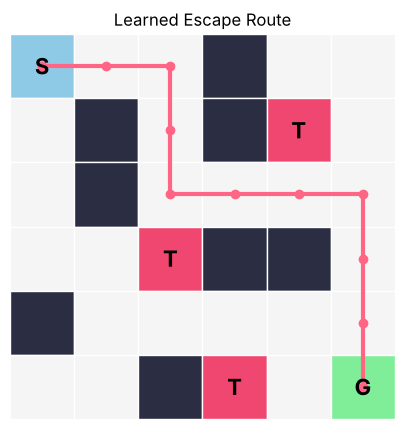

In [7]:
print("LEARNED POLICY (greedy w.r.t. Q)\n")
for r in range(ROWS):
    line = ""
    for c in range(COLS):
        cell = MAZE[r][c]
        if cell in ("#", "G", "T"):
            line += f" {cell} "
        else:
            q = Q[(r, c)]
            line += f" {ARROWS[int(np.argmax(q))] if q.any() else '?'} "
    print(line)
print("\n(# wall, T trap, G goal)")

env = MazeEscape(MAZE)
s, done, path, total = env.reset(), False, [env.start], 0
while not done:
    s, r, done = env.step(int(np.argmax(Q[s])))
    path.append(s); total += r
print("\nGreedy path:", " -> ".join(map(str, path)))
print("Steps:", len(path) - 1, "| Total reward:", total)
draw_maze(path, "Learned Escape Route")

## 8. Cumulative Reward per Episode

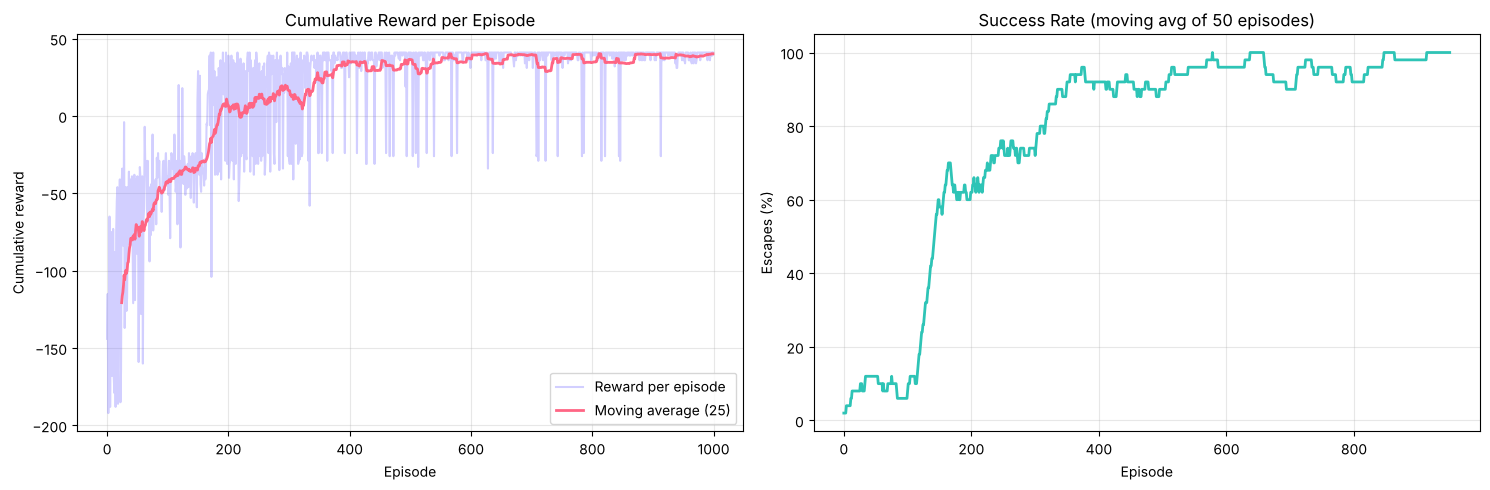

Average reward, first 100 episodes: -74.01
Average reward, last 100 episodes : 38.78


In [8]:
w = 25
ma = np.convolve(rewards_per_episode, np.ones(w)/w, mode="valid")
sr = np.convolve(success, np.ones(50)/50, mode="valid") * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(rewards_per_episode, alpha=0.3, color="#6C63FF", label="Reward per episode")
ax[0].plot(range(w-1, len(rewards_per_episode)), ma, color="#FF6584", lw=2, label=f"Moving average ({w})")
ax[0].set_title("Cumulative Reward per Episode"); ax[0].set_xlabel("Episode"); ax[0].set_ylabel("Cumulative reward")
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(sr, color="#2EC4B6", lw=2)
ax[1].set_title("Success Rate (moving avg of 50 episodes)"); ax[1].set_xlabel("Episode"); ax[1].set_ylabel("Escapes (%)")
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"Average reward, first 100 episodes: {np.mean(rewards_per_episode[:100]):.2f}")
print(f"Average reward, last 100 episodes : {np.mean(rewards_per_episode[-100:]):.2f}")

## 9. Discussion of Results
* **Early episodes:** ε is high, so the agent wanders randomly, hits walls and falls into traps → very negative reward.
* **Middle episodes:** returns from the exit propagate backwards through the Q-values, so reward rises quickly.
* **Late episodes:** ε reaches 0.05, reward stabilises near +38 and the agent escapes in ~99% of episodes.
* The learned route has **10 steps** and earns **+41** (9 × −1 + 50), the optimal path in this maze.
* The incremental mean equals the average of all observed returns but needs only constant memory per `(s,a)`.
* **Limitations:** Monte Carlo needs complete episodes and has high variance early on. Temporal-Difference methods (Q-learning, SARSA) are a natural next step.